In [27]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

In [28]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [29]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [30]:
class State(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[str], operator.add]
    final: str

In [31]:
llm = ChatGroq(model="openai/gpt-oss-20b")

In [32]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

In [33]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [34]:
def worker(payload: dict) -> dict:

    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [35]:
from pathlib import Path
import re

def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    filename = re.sub(r'[<>:"/\\|?*]', "", title.lower())
    filename = filename.replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [36]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

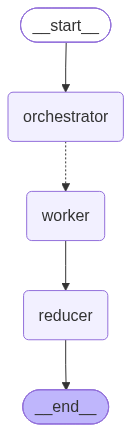

In [37]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [25]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})

In [26]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Understanding Self-Attention: The Backbone of Modern NLP', tasks=[Task(id=1, title='Introduction to Attention Mechanisms', brief='Explain the evolution from traditional models to attention-based architectures, setting the stage for self-attention.'), Task(id=2, title='Mathematical Foundations of Self-Attention', brief='Break down the query, key, value matrices, dot-product scaling, and softmax operations in an accessible way.'), Task(id=3, title='Self-Attention in Transformer Models', brief='Illustrate how self-attention replaces recurrence in Transformers, highlighting encoder and decoder roles.'), Task(id=4, title='Practical Implementation Guide', brief='Provide a step-by-step TensorFlow/PyTorch code snippet to build a basic self-attention layer.'), Task(id=5, title='Common Variants and Enhancements', brief='Discuss multi-head attention, relative positional encodings, and efficient attention approximations.'), Task